## Code for generating figures 7E, S11, S12

In [ ]:
import mne
import pandas as pd
import mtrf
from mtrf.model import TRF
from mtrf.stats import crossval, nested_crossval


import matplotlib.pyplot as plt
import matplotlib as mpl
plt.style.use("article.mplstyle")
import numpy as np
import scipy
import seaborn as sns


from scipy.io import loadmat, savemat
from scipy.stats import pearsonr
from pingouin import rm_anova


from statannotations.Annotator import Annotator
from itertools import combinations
from collections import Counter

import sys
sys.path.append('../utils')
from pp_utils import *
from plot_utils import *
from mTRF_utils import *
from midi_utils import *
from update_sub_lists import*
from ERP_utils import *


import pickle
import os

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)


## Set up directories

In [123]:

train = 'listen'

mapchange_dir = '../analysis_error/mapchange_csv_corrected_since_bymap_till/'
pred_dir = f'../analysis_error/mtrf_error_surprise/rTRF_predictions_{train}'
sv_dir ='../analysis_error/mtrf_error_surprise/sv'
good_listen_subjects, good_motor_subjects,good_error_subjects,musicians,nonmusicians = load_subject_lists_LME()



In [124]:
xtick_fontsize = 15
axis_fontsize = 20

## Visualize individual predictions

In [ ]:
# subject = '06'
# period = 'post'

# # pred_data = loadmat(os.path.join(pred_dir, f'pred_err_{subject}_{period}.mat'))
# # pred_stim = pred_data['predicted_stim'][0]
# # pred_corr = pred_data['pearsonr']
# # sv_onsets = loadmat(os.path.join(sv_dir, f'sv_data_{period}_{subject}.mat'))['onsets'][0]
# # sv_firsts = loadmat(os.path.join(sv_dir, f'sv_data_{period}_{subject}.mat'))['firsts'][0]

# # print(pred_corr)

# pred_stim_winsorized = winsorize(pred_stim, limits = [0.005, 0.005])

In [126]:
# plt.figure(figsize = (15,5))
# plt.plot(sv_firsts/8, label = 'scaled ground truth')
# plt.plot(pred_stim_winsorized, alpha = 0.8, label = 'pred')
# plt.title(f'{subject} {period}')
# plt.legend()

# plt.xlim(30000,40000)

In [127]:
# pearsonr(pred_stim_winsorized, sv_onsets)

## Correlate with support vectors

In [ ]:

periods =[ 'pre', 'post']
subjects_to_process =  good_error_subjects

pearson_o_stat = []
pearson_o_p = []
pearson_shuf_stat = []
pearson_shuf_p = []

corr_sv_df = pd.DataFrame()

for subject in subjects_to_process:
    for period in periods:

        sub_df = {
            'subject': subject,
            'period': period
        }
    # print(subject)
        pred_data = loadmat(os.path.join(pred_dir, f'pred_err_{subject}_{period}.mat'))
        pred_stim = pred_data['predicted_stim'][0]
        # print(pred_stim.shape)

        #load support vectors
        sv_onsets = loadmat(os.path.join(sv_dir, f'sv_data_{period}_{subject}.mat'))['onsets'][0] 
        sv_firsts = loadmat(os.path.join(sv_dir, f'sv_data_{period}_{subject}.mat'))['firsts'][0] 

        if sv_firsts.shape[0]>pred_stim.shape[0]:
            # sv_firsts = sv_firsts[:pred_stim.shape[0]]
            sv_onsets = sv_onsets[:pred_stim.shape[0]]

        
        #correlation with support vectors
        try:
            #correlation with onsets
            res_o = pearsonr(pred_stim, sv_onsets) 
            sub_df['pearson_onsets_stat'] = res_o.statistic
            sub_df['pearson_onsets_p'] = res_o.pvalue
            # pearson_o_stat.append(res_o.statistic)
            # pearson_o_p.append(res_o.pvalue)

            #correlation with shuffled onsets
            res_o_shuf = pearsonr(pred_stim, np.random.permutation(sv_onsets))
            sub_df['pearson_shuffled_stat'] = res_o_shuf.statistic
            sub_df['pearson_shuffled_p'] = res_o_shuf.pvalue
            # pearson_shuf_stat.append(res_o_shuf.statistic)
            # pearson_shuf_p.append(res_o_shuf.pvalue)

            corr_sv_df = pd.concat([corr_sv_df, pd.DataFrame([sub_df])], ignore_index=True)
        except ValueError: 
            print('ValueError at subject', subject)
            continue


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

post_pearson_onsets_stat vs. post_pearson_shuffled_stat: Custom statistical test, P_val:7.629e-06
pre_pearson_onsets_stat vs. pre_pearson_shuffled_stat: Custom statistical test, P_val:7.629e-06


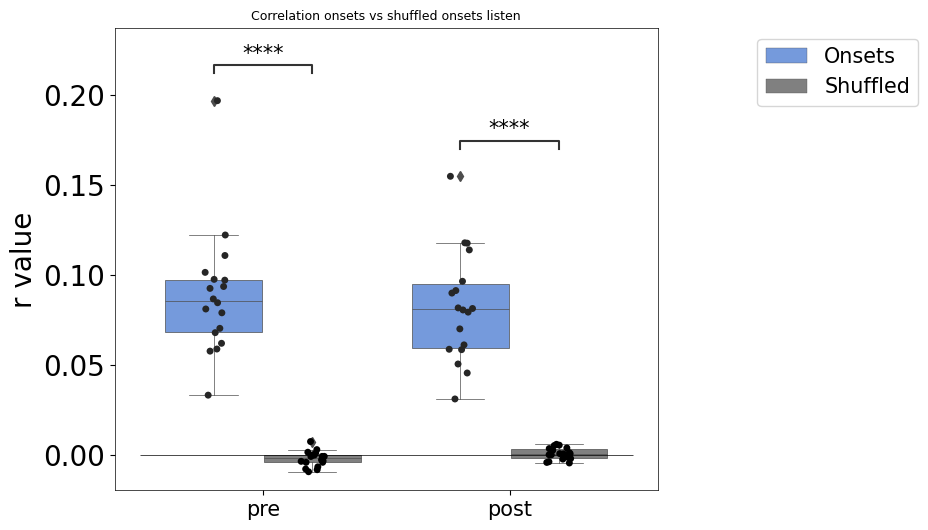

In [ ]:
plt.figure(figsize = (7,6))
colours = {
    'pearson_onsets_stat': 'cornflowerblue',
    'pearson_shuffled_stat': 'grey'
}

corr_sv_df_sns = pd.melt(corr_sv_df, id_vars = ['subject', 'period'], value_vars = ['pearson_onsets_stat', 'pearson_shuffled_stat'], var_name = 'correlation_type', value_name = 'correlation_value')
ax = sns.boxplot(corr_sv_df_sns, x = 'period', y = 'correlation_value', hue = 'correlation_type', palette = colours)
sns.stripplot(corr_sv_df_sns, x = 'period', y = 'correlation_value', hue = 'correlation_type', color = 'black', dodge = True)



#stat annotations
pairs = [(('pre','pearson_onsets_stat'), ('pre','pearson_shuffled_stat')),
         (('post','pearson_onsets_stat'), ('post','pearson_shuffled_stat'))]

#manually calculate p values
_, p_pre = wilcoxon(corr_sv_df.query('period == "pre"')['pearson_onsets_stat'], corr_sv_df.query('period == "pre"')['pearson_shuffled_stat'])
_, p_post = wilcoxon(corr_sv_df.query('period == "post"')['pearson_onsets_stat'], corr_sv_df.query('period == "post"')['pearson_shuffled_stat'])

annotator = Annotator(ax, pairs, data=corr_sv_df_sns, x='period', y='correlation_value', hue = 'correlation_type')
annotator.configure(text_format='star', loc='inside', fontsize=15)
annotator.set_pvalues([p_pre, p_post])

annotator.annotate()


ax = plt.gca()

ax.set_xticklabels(['pre', 'post'], fontsize = xtick_fontsize)
plt.title(f'Correlation onsets vs shuffled onsets {train}')
plt.ylabel('r value', fontsize = axis_fontsize)
plt.xlabel('')
plt.yticks(fontsize = axis_fontsize)
plt.hlines(0, -0.5, 1.5, color = 'black')
plt.legend(title = '', fontsize = xtick_fontsize,  bbox_to_anchor=(1.5, 1))

label_map = {
    'pearson_onsets_stat': 'Onsets',
    'pearson_shuffled_stat': 'Shuffled'
}
handles, labels = ax.get_legend_handles_labels()
new_labels = [label_map.get(l, l) for l in labels]
ax.legend(handles[:2], new_labels[:2], title='', fontsize=xtick_fontsize, bbox_to_anchor=(1.5, 1))



## Firsts vs others

In [ ]:
n_samples = 100
rng = np.random.default_rng(42)


periods = ['pre', 'post']
pred_amp_df = []
subjects_to_process = good_error_subjects

for subject in subjects_to_process:
    print(subject)
    for period in periods:

        sub_data = {
            'subject': subject,
            'period': period
        }
        

        #look at predictions with time-matched models
        pred_data = loadmat(os.path.join(pred_dir, f'pred_err_{subject}_{period}.mat'))
        pred_stim = pred_data['predicted_stim'][0]

        #find times for keystrokes
        fo_df = pd.read_csv(os.path.join(mapchange_dir,f'mapchange_keystrokes_{period}_{subject}.csv'))
        others_times = fo_df[fo_df['type']=='other']['time']
        firsts_times = fo_df[fo_df['type']=='first']['time']



        firsts_sel = rng.choice(
            firsts_times,
            size=min(100, len(firsts_times)),
            replace=False
        )

        others_sel = rng.choice(
            others_times,
            size=min(100, len(firsts_times)),
            replace=False
)

        amp_firsts = pred_stim[firsts_sel].mean()
        amp_others = pred_stim[others_sel].mean()


        sub_data['others'] = amp_others
        sub_data['firsts'] = amp_firsts

        pred_amp_df.append(sub_data)    

pred_amp_df = pd.DataFrame(pred_amp_df)



01
04
05
06
07
08
09
10
11
12
13
14
15
16
17
18
19
20


In [138]:
pred_amp_df['diff'] = pred_amp_df['firsts'] - pred_amp_df['others']

pred_amp_df_melt = pred_amp_df.melt(id_vars=['subject', 'period'], 
                 value_vars = ['others', 'firsts'], 
                 value_name = 'pred_amp',
                 var_name='type')

In [139]:

anova_res = rm_anova(data = pred_amp_df_melt, dv = 'pred_amp', within = ['period', 'type'], subject = 'subject')
anova_res


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,period,0.000155,1,17,0.000155,3.724873,0.070466,0.070466,0.030179,1.0
1,type,0.000139,1,17,0.000139,23.675575,0.000145,0.000145,0.027047,1.0
2,period * type,0.000006,1,17,0.000006,2.765849,0.114620,0.114620,0.001139,1.0


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

post_others vs. post_firsts: Custom statistical test, P_val:1.907e-04
pre_others vs. pre_firsts: Custom statistical test, P_val:3.281e-04
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pre vs. post: Wilcoxon test (paired samples), P_val:6.000e-03 Stat=1.610e+02


/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


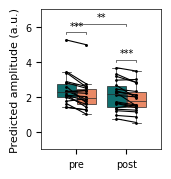

In [ ]:
fig = plt.figure(figsize = (1.2,1.4))
ax = fig.add_axes([0,0,1,1])

fo_colours = {'firsts': 'teal', 'others': 'coral'}
flierprops = dict(marker='o', markersize=1, linestyle='none', markerfacecolor='gray', alpha=0.6)

ax = sns.boxplot(data = pred_amp_df_melt, x = 'period', y = 'pred_amp', hue = 'type', 
                 hue_order=['firsts', 'others'], palette=fo_colours, flierprops=flierprops)

#plot individual subject lines
for period in periods:
    if period == 'pre':
        x_pos =  [-0.2, 0.2]
    elif period == 'post':
        x_pos = [0.8, 1.2]

    for subject in subjects_to_process:

        amp_toplot = pred_amp_df_melt.query(f'subject == "{subject}" and period == "{period}"')
        amp_firsts = amp_toplot.query(f'type == "firsts"')['pred_amp'].values[0]
        amp_others = amp_toplot.query(f'type == "others"')['pred_amp'].values[0]
    
        ax.plot(x_pos, [amp_firsts, amp_others], color = 'black', marker = 'o', markersize = 1, linewidth = 0.8)


_, p_pre = wilcoxon(pred_amp_df_melt.query('period == "pre" & type == "firsts"')['pred_amp'], pred_amp_df_melt.query('period == "pre" & type == "others"')['pred_amp'])
_, p_post = wilcoxon(pred_amp_df_melt.query('period == "post" & type == "firsts"')['pred_amp'], pred_amp_df_melt.query('period == "post" & type == "others"')['pred_amp'])


#firsts vs others within the period
pairs = [(('pre', 'firsts'), ('pre', 'others')),(('post', 'firsts'), ('post', 'others'))]
annotator = Annotator(ax, pairs, data=pred_amp_df_melt, x='period', y='pred_amp', hue='type')
annotator.set_pvalues([p_pre, p_post])
annotator.configure(fontsize = mpl.rcParams['xtick.labelsize'],
                    line_width = mpl.rcParams['lines.linewidth'])
annotator.annotate()

#Pre vs post main effect
pairs = [("pre", "post")]
annot = Annotator(ax, pairs, data=pred_amp_df_melt, x='period', y='pred_amp')
annot.configure(test='Wilcoxon', text_format='star', loc='inside', verbose=2, 
                fontsize = mpl.rcParams['xtick.labelsize'],
                    line_width = mpl.rcParams['lines.linewidth'])
annot.apply_and_annotate()

ax.legend_.remove()

# plt.legend(title = '', bbox_to_anchor=(1.5, 1))
plt.ylabel('Predicted amplitude')
plt.ylabel('Predicted amplitude (a.u.)')
plt.yticks([0, 0.02, 0.04, 0.06])
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x * 1e2)}')) 

plt.ylim(-0.01, 0.07)
plt.xlabel('')
plt.savefig(f'./figures/pred_prepost_{train}_sizematched.svg')

## Reconstructed stim window

In [ ]:
mapchange_dir_bymap = '../analysis_error/mapchange_csv_corrected_since_bymap_till/'
periods = ['pre', 'post']
pred_amp_df_window = []
# subjects_to_process = ['01','04','05','06','07','08','09','10','11','12']
subjects_to_process = ['01','04','05','06','07','08','09','10','11','12', '13', '14', '15', '16', '18', '19', '20']

window = 20
map_to_plot = 'norm'

for subject in subjects_to_process:
    for period in periods:

        sub_data = {
            'subject': subject,
            'period': period
        }

        pred_data = loadmat(os.path.join(pred_dir, f'pred_err_{subject}_{period}.mat'))
        pred_stim = pred_data['predicted_stim'][0]
        
        fo_df = pd.read_csv(os.path.join(mapchange_dir_bymap,f'mapchange_keystrokes_{period}_{subject}.csv'))

        #find times for keystrokes
        if map_to_plot == 'all_maps':
            others_times = fo_df[fo_df['type']=='other']['time']
            firsts_times = fo_df[fo_df['type']=='first']['time']

        else:
            others_times = fo_df[(fo_df['type']=='other') & (fo_df['prev_map'] == map_to_plot)]['time']
            firsts_times = fo_df[(fo_df['type']=='first') & (fo_df['prev_map'] == map_to_plot)]['time']

        window_others = np.array([pred_stim[max(0, t-window) : min(len(pred_stim), t+window+1)] for t in others_times])
        window_firsts = np.array([pred_stim[max(0, t-window) : min(len(pred_stim), t+window+1)] for t in firsts_times])

        #average to get mean window shape
        sub_data['others'] = np.expand_dims(np.mean(window_others, axis = 0), axis = 0)
        sub_data['firsts'] = np.expand_dims(np.mean(window_firsts, axis = 0), axis = 0)


    
        pred_amp_df_window.append(sub_data)    

pred_amp_df_window = pd.DataFrame(pred_amp_df_window)

(0.0, 0.03)

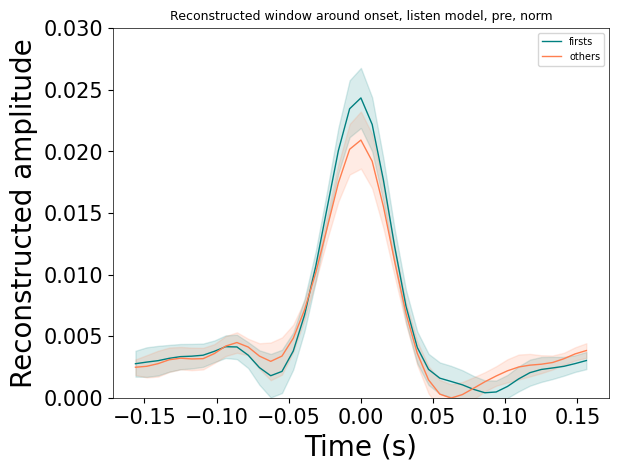

In [144]:

period = 'pre'
mean_firsts, sem_firsts = find_mean_sem_evs(pred_amp_df_window.query(f'period == "{period}"'), 0, col_to_ave='firsts')
mean_others, sem_others = find_mean_sem_evs(pred_amp_df_window.query(f'period == "{period}"'), 0, col_to_ave='others')

erp_times = create_erp_times(-0.15625, 0.15625, 128)
plot_mean_sem(erp_times, mean_firsts, sem_firsts, color = 'teal', label = 'firsts')
plot_mean_sem(erp_times, mean_others, sem_others, color = 'coral', label = 'others')
plt.legend()
plt.title(f'Reconstructed window around onset, {train} model, {period}, {map_to_plot}')
plt.ylabel('Reconstructed amplitude', fontsize = axis_fontsize)
plt.xlabel('Time (s)', fontsize = axis_fontsize)
plt.yticks(fontsize = xtick_fontsize)
plt.xticks(fontsize = xtick_fontsize)
plt.ylim(0, 0.03)


## First vs other reconstruction by map

In [ ]:
mapchange_dir_bymap = '../mapchange_csv_corrected_since_bymap_till/'

periods = ['pre', 'post']
pred_stim_data = []
subjects_to_process = good_error_subjects
window = 20
maps = ['inv', 'shinv', 'norm']
epoch_types = ['first', 'other']

for subject in subjects_to_process:
    for period in periods:

        sub_data = {
            'subject': subject,
            'period': period
        }

        pred_data = loadmat(os.path.join(pred_dir, f'pred_err_{subject}_{period}.mat'))
        pred_stim = pred_data['predicted_stim'][0]
        
        fo_df = pd.read_csv(os.path.join(mapchange_dir_bymap,f'mapchange_keystrokes_{period}_{subject}.csv'))

        for epoch_type in epoch_types:

            times = fo_df[(fo_df['type'] == epoch_type)]['time']

            if len(times) > 0:
                window_data = np.array([pred_stim[max(0, t-window) : min(len(pred_stim), t+window+1)] for t in times])
                sub_data[epoch_type] = np.expand_dims(np.mean(window_data, axis=0), axis=0)

            #average windows for each new map
            for map_type in maps:

                if epoch_type == 'first': #first in the map for entering, first leaving the map for leaving
                    map_times = fo_df[(fo_df['type'] == epoch_type) & (fo_df['map'] == map_type)]['time']
                    prevmap_times = fo_df[(fo_df['type'] == epoch_type) & (fo_df['prev_map'] == map_type)]['time']
                elif epoch_type == 'other': #other in the map for both entering and leaving
                    map_times = fo_df[(fo_df['type'] == epoch_type) & (fo_df['map'] == map_type)]['time']
                    prevmap_times = map_times.copy()
                    
                if len(map_times) > 0:
                    map_window = np.array([pred_stim[max(0, t-window) : min(len(pred_stim), t+window+1)] for t in map_times])
                    prevmap_window = np.array([pred_stim[max(0, t-window) : min(len(pred_stim), t+window+1)] for t in prevmap_times])

                    sub_data[f'{epoch_type}{map_type}'] = np.expand_dims(np.mean(map_window, axis=0), axis=0)
                    sub_data[f'{epoch_type}{map_type}prev'] = np.expand_dims(np.mean(map_window, axis=0), axis=0)


        pred_stim_data.append(sub_data)    

pred_stim_df = pd.DataFrame(pred_stim_data)


FileNotFoundError: [Errno 2] No such file or directory: '../mapchange_csv_corrected_since_bymap_till/mapchange_keystrokes_pre_01.csv'

In [ ]:
pairs =[ ('firstinv', 'otherinv'),
        ('firstshinv', 'othershinv'),
        ('firstnorm', 'othernorm'), 
        
        ('firstinvprev', 'otherinvprev'),
        ('firstshinvprev', 'othershinvprev'),
        ('firstnormprev', 'othernormprev')
]

for pair in pairs: 
    col_1 = pair[0]
    col_2 = pair[1]
    pred_stim_df['diff_'+pair[0]+"_"+pair[1]] = pred_stim_df[col_1] - pred_stim_df[col_2]


In [ ]:
def peak_regions_max(x, ch_idx, t_idx):
    x_ch_mean = np.mean(x[ch_idx], axis =0)
    x_ch_time_max = np.max(x_ch_mean[t_idx[0]:t_idx[1]])
    return x_ch_time_max

def peak_regions_min(x, ch_idx, t_idx):
    x_ch_mean = np.mean(x[ch_idx], axis =0)
    x_ch_time_max = np.min(x_ch_mean[t_idx[0]:t_idx[1]])
    return x_ch_time_max

def peak_regions_mean(x, ch_idx, t_idx):
    x_ch_mean = np.mean(x[ch_idx], axis =0)
    x_ch_time_max = np.mean(x_ch_mean[t_idx[0]:t_idx[1]])
    return x_ch_time_max

In [ ]:
#select timepoints and channels of interest
ch_to_test = ['Fz', 'FCz', 'Cz', 'F1', 'FC1', 'C1', 'C2', 'FC2', 'F2']
#time_to_plot = [0.08, 0.12]
#time_to_plot = [0.055, 0.065]
# time_to_plot = [0.325, 0.375]
time_to_plot = [-0.005, 0.005]
peakfinder = peak_regions_max

ch_idx = [0]
time_idx = time_index_custom(time_to_plot, erp_times)


diffs = ['diff_firstinv_otherinv', 'diff_firstshinv_othershinv',
       'diff_firstnorm_othernorm', 'diff_firstinvprev_otherinvprev',
       'diff_firstshinvprev_othershinvprev',
       'diff_firstnormprev_othernormprev']

for diff in diffs:
    pred_stim_df['amp_'+diff] = pred_stim_df[diff].apply(lambda x: peakfinder(x, ch_idx, time_idx))

pred_stim_df_sns = pd.melt(pred_stim_df, id_vars=['subject', 'period'], value_vars= ['amp_' + diff for diff in diffs], var_name='map', value_name='amplitude')


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pre_amp_diff_firstinvprev_otherinvprev vs. post_amp_diff_firstinvprev_otherinvprev: Wilcoxon test (paired samples), P_val:9.661e-01 Stat=8.400e+01
pre_amp_diff_firstinv_otherinv vs. post_amp_diff_firstinv_otherinv: Wilcoxon test (paired samples), P_val:9.661e-01 Stat=8.400e+01
pre_amp_diff_firstshinvprev_othershinvprev vs. post_amp_diff_firstshinvprev_othershinvprev: Wilcoxon test (paired samples), P_val:1.297e-01 Stat=5.000e+01
pre_amp_diff_firstshinv_othershinv vs. post_amp_diff_firstshinv_othershinv: Wilcoxon test (paired samples), P_val:1.297e-01 Stat=5.000e+01
pre_amp_diff_firstnormprev_othernormprev vs. post_amp_diff_firstnormprev_othernormprev: Wilcoxon test (paired samples), P_val:6.397e-01 Stat=7.400e+01
pre_amp_diff_firstnorm_othernorm vs. post_amp_diff_firstnorm_othernorm: Wilcoxon test

/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype

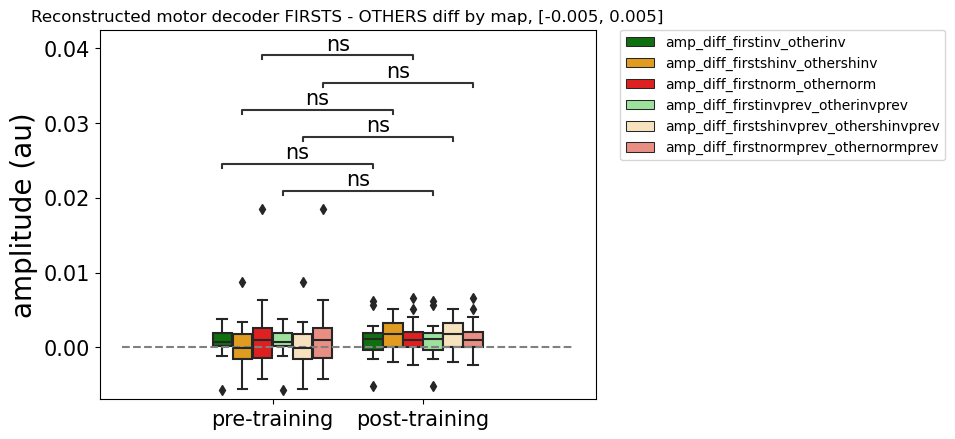

In [ ]:


palette =  {'amp_diff_firstinv_otherinv':'green', 
            'amp_diff_firstshinv_othershinv': 'orange',
       'amp_diff_firstnorm_othernorm': 'red',
         'amp_diff_firstinvprev_otherinvprev':'lightgreen',
       'amp_diff_firstshinvprev_othershinvprev':'moccasin',
       'amp_diff_firstnormprev_othernormprev':'salmon'}

ax=sns.boxplot(pred_stim_df_sns, x = 'period', y = 'amplitude', hue = 'map', palette=palette)



pairs = [
     (("pre", "amp_diff_firstinvprev_otherinvprev"), ("post", "amp_diff_firstinvprev_otherinvprev")),
      (("pre", "amp_diff_firstinv_otherinv"), ("post", "amp_diff_firstinv_otherinv")),
      (("pre", "amp_diff_firstshinvprev_othershinvprev"), ("post", "amp_diff_firstshinvprev_othershinvprev")),
      (("pre", "amp_diff_firstshinv_othershinv"), ("post", "amp_diff_firstshinv_othershinv")),
      (("pre", "amp_diff_firstnormprev_othernormprev"), ("post", "amp_diff_firstnormprev_othernormprev")),
      (("pre", "amp_diff_firstnorm_othernorm"), ("post", "amp_diff_firstnorm_othernorm"))
    ]



annot = Annotator(ax, pairs, data=pred_stim_df_sns, x='period', y='amplitude', hue='map')
annot.configure(test='Wilcoxon', text_format='star', loc='inside', verbose=2, fontsize = 15)
annot.apply_and_annotate()
    
#formatting
plt.title(f'Reconstructed {train} decoder FIRSTS - OTHERS diff by map, {time_to_plot}')
plt.xlabel('')
plt.yticks(fontsize=xtick_fontsize)
plt.xticks([0, 1], ['pre-training', 'post-training'], fontsize = xtick_fontsize)    
plt.ylabel('amplitude (au)', fontsize = axis_fontsize)
ax.hlines(0,-1, 2, linestyles = '--', color = 'grey')

ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)

